In [1]:
import os
import time
import json
import requests
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from datetime import datetime, timedelta
from dotenv import load_dotenv, find_dotenv

In [5]:
load_dotenv(find_dotenv())
PLANET_API_KEY = os.getenv("PLANET_API_KEY")

if not PLANET_API_KEY:
    raise ValueError("Brak klucza! Upewnij się, że masz plik .env z PLANET_API_KEY")
SEARCH_URL = "https://api.planet.com/data/v1/quick-search"
GEOJSON_PATH = "../results/geojson/wegrzce_aoi-06-10.geojson"
UAV_TIF_PATH = "../Wegrzce_tify/01W0610.tif"  


TARGET_DATE = "2026-10-06"  
MAX_DAYS_DIFF = 5           
MAX_CLOUD = 0.03           

UAV_RED_BAND = 15
UAV_NIR_BAND = 21
NDVI_SOIL_THRESHOLD = 0.1
eps = 1e-8

In [3]:
print("1. Wczytuję plik GeoJSON pola...")
with open(GEOJSON_PATH, "r") as f:
    geojson_data = json.load(f)
aoi_geometry = geojson_data["features"][0]["geometry"]

# KROK 2: Wyszukanie zdjęcia najbliżej 15 września
target_dt = datetime.strptime(TARGET_DATE, "%Y-%m-%d")
start_dt = (target_dt - timedelta(days=MAX_DAYS_DIFF)).strftime("%Y-%m-%dT00:00:00.000Z")
end_dt = (target_dt + timedelta(days=MAX_DAYS_DIFF)).strftime("%Y-%m-%dT23:59:59.000Z")

print(f"2. Szukam bezchmurnego zdjęcia jak najbliżej daty {TARGET_DATE}...")

search_request = {
    "item_types": ["PSScene"],
    "filter": {
        "type": "AndFilter",
        "config": [
            {"type": "GeometryFilter", "field_name": "geometry", "config": aoi_geometry},
            {"type": "DateRangeFilter", "field_name": "acquired", "config": {"gte": start_dt, "lte": end_dt}},
            {"type": "RangeFilter", "field_name": "cloud_cover", "config": {"lte": MAX_CLOUD}},
            {"type": "AssetFilter", "config": ["ortho_analytic_8b_sr", "ortho_analytic_4b_sr"]}
        ]
    }
}

res = requests.post(
    "https://api.planet.com/data/v1/quick-search",
    auth=(PLANET_API_KEY, ""),
    json=search_request
)
res.raise_for_status()
features = res.json().get("features", [])

if not features:
    raise ValueError(f"Brak bezchmurnych zdjęć w oknie +/- {MAX_DAYS_DIFF} dni od {TARGET_DATE}!")

kandydaci = []
for feat in features:
    acq_str = feat["properties"]["acquired"][:10]
    acq_dt = datetime.strptime(acq_str, "%Y-%m-%d")
    
    # Różnica dni w wartość bezwzględną (np. 16.09 -> 1 dzień, 13.09 -> 2 dni)
    diff_days = abs((acq_dt - target_dt).days)
    clouds = feat["properties"]["cloud_cover"]
    assets = feat.get("assets", [])
    
    bundle = "analytic_8b_sr_udm2" if "ortho_analytic_8b_sr" in assets else "analytic_sr_udm2"
    kandydaci.append((diff_days, clouds, feat["id"], acq_str, bundle))

# Sortowanie: najpierw najmniejsza różnica dni (diff_days), a przy remisie mniej chmur (clouds)
kandydaci.sort(key=lambda x: (x[0], x[1]))

diff_days, clouds, target_feature, best_date, product_bundle = kandydaci[0]
print(f"-> Wybrano zdjęcie z dnia: {best_date} (różnica: {diff_days} dni, chmury: {clouds*100:.1f}%, ID: {target_feature})")

# Zamówienie i przycięcie zdjęcia do GeoJSON-a (Orders API)
print("Zlecam przycięcie i przygotowanie pliku w Planet Orders API...")
order_request = {
    "name": f"Wegrzce_{best_date}",
    "products": [{
        "item_ids": [target_feature],
        "item_type": "PSScene",
        "product_bundle": product_bundle
    }],
    "tools": [{
        "clip": {"aoi": aoi_geometry}
    }]
}

order_res = requests.post(
    "https://api.planet.com/compute/ops/orders/v2",
    auth=(PLANET_API_KEY, ""),
    json=order_request
)

# --- TIP DEBUGOWANIA ---
# Jeśli nadal wyrzuci błąd 400, to wyświetli dokładny powód z serwera Planet
if order_res.status_code != 200 and order_res.status_code != 202:
    print("Szczegóły błędu Planet API:", order_res.text)

order_res.raise_for_status()
order_id = order_res.json()["id"]

download_url = None
while True:
    poll_res = requests.get(f"https://api.planet.com/compute/ops/orders/v2/{order_id}", auth=(PLANET_API_KEY, ""))
    state = poll_res.json().get("state")
    print(f"   Status zamówienia na serwerze Planet: {state}...")
    if state == "success":
        results = poll_res.json().get("_links", {}).get("results", [])
        for r in results:
            path_name = r.get("name", "")
            if path_name.endswith(".tif") and "SR" in path_name.upper() and "UDM" not in path_name.upper():
                download_url = r["location"]
                break
        break
    elif state in ["failed", "cancelled"]:
        raise RuntimeError(f"Zamówienie w Planet API zakończyło się błędem: {state}")
    time.sleep(10)

sat_tif_path = f"../results/planet/planet_{best_date}.tif"
os.makedirs("../results/planet", exist_ok=True)
with open(sat_tif_path, "wb") as f:
    f.write(requests.get(download_url).content)
print(f"Pobrano przycięty plik satelitarny: {sat_tif_path}")

1. Wczytuję plik GeoJSON pola...
2. Szukam bezchmurnego zdjęcia jak najbliżej daty 2026-10-06...
-> Wybrano zdjęcie z dnia: 2026-10-06 (różnica: 0 dni, chmury: 2.0%, ID: 20261006_104048_01_2514)
Zlecam przycięcie i przygotowanie pliku w Planet Orders API...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamówienia na serwerze Planet: running...
   Status zamó

In [6]:
print("3. Przetwarzam dane z drona (odcinam glebę NDVI <= 0.1) i robię upscaling do 3x3 m...")

with rasterio.open(UAV_TIF_PATH) as src_uav:
    uav_crs = src_uav.crs
    uav_transform = src_uav.transform
    uav_bounds = src_uav.bounds

    red_uav = src_uav.read(UAV_RED_BAND).astype(np.float32)
    nir_uav = src_uav.read(UAV_NIR_BAND).astype(np.float32)

    valid_uav = (red_uav > 0) & (nir_uav > 0)
    ndvi_uav_3cm = np.full(red_uav.shape, np.nan, dtype=np.float32)
    ndvi_uav_3cm[valid_uav] = (nir_uav[valid_uav] - red_uav[valid_uav]) / (nir_uav[valid_uav] + red_uav[valid_uav] + eps)

    # Odcięcie gołej gleby na dronie
    ndvi_uav_3cm[ndvi_uav_3cm <= NDVI_SOIL_THRESHOLD] = np.nan

with rasterio.open(sat_tif_path) as src_sat:
    sat_crs = src_sat.crs
    bounds_in_sat_crs = transform_bounds(uav_crs, sat_crs, *uav_bounds)
    window = from_bounds(*bounds_in_sat_crs, transform=src_sat.transform).round_offsets().round_lengths()

    sat_transform = src_sat.window_transform(window)
    sat_height, sat_width = int(window.height), int(window.width)

    if src_sat.count == 8:
        red_idx, nir_idx = 6, 8
    else:
        red_idx, nir_idx = 3, 4

    red_sat = src_sat.read(red_idx, window=window).astype(np.float32) / 10000.0
    nir_sat = src_sat.read(nir_idx, window=window).astype(np.float32) / 10000.0

    valid_sat = (red_sat > 0) & (nir_sat > 0)
    ndvi_sat_3m = np.full((sat_height, sat_width), np.nan, dtype=np.float32)
    ndvi_sat_3m[valid_sat] = (nir_sat[valid_sat] - red_sat[valid_sat]) / (nir_sat[valid_sat] + red_sat[valid_sat] + eps)

ndvi_uav_3m = np.full((sat_height, sat_width), np.nan, dtype=np.float32)
reproject(
    source=ndvi_uav_3cm, destination=ndvi_uav_3m,
    src_transform=uav_transform, src_crs=uav_crs, src_nodata=np.nan,
    dst_transform=sat_transform, dst_crs=sat_crs, dst_nodata=np.nan,
    resampling=Resampling.average
)

3. Przetwarzam dane z drona (odcinam glebę NDVI <= 0.1) i robię upscaling do 3x3 m...


(array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]], shape=(71, 62), dtype=float32),
 Affine(3.0, 0.0, 427266.0,
        0.0, -3.0, 5552298.0))

4. Generuję zestawienie map i wykres korelacji...
Gotowe! Mapy i wykres zapisano w: ../results/ndvi/ndvi_2026-10-06.png


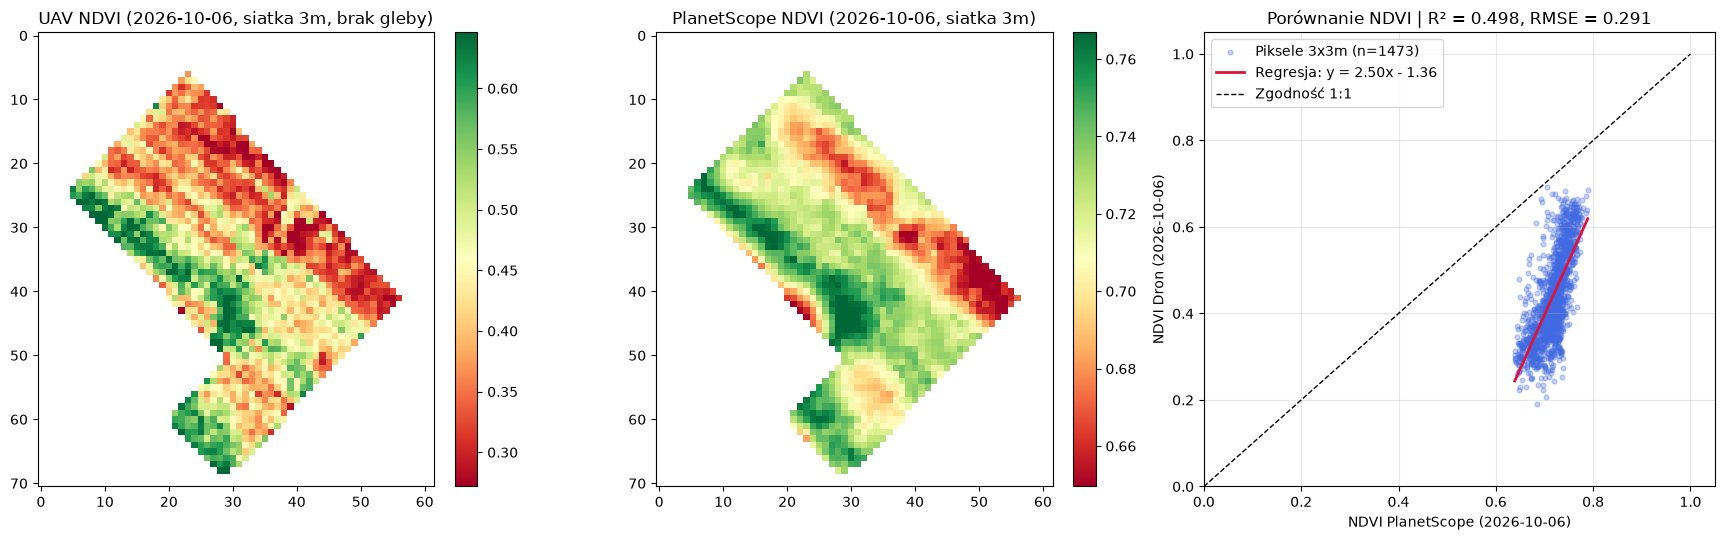

In [7]:
# KROK 4: Generowanie map obok siebie i wykresu korelacji
print("4. Generuję zestawienie map i wykres korelacji...")
maska = ~np.isnan(ndvi_uav_3m) & ~np.isnan(ndvi_sat_3m)
x_sat = ndvi_sat_3m[maska]
y_uav = ndvi_uav_3m[maska]

r_corr, _ = pearsonr(x_sat, y_uav)
r2 = r_corr**2
rmse = np.sqrt(mean_squared_error(y_uav, x_sat))
a, b = np.polyfit(x_sat, y_uav, 1)

# Tworzymy figurę z 3 panelami obok siebie (1 wiersz, 3 kolumny)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Ustawiamy indywidualne skale kolorów (2-98 percentyl) dla każdego sensora,
# żeby uwidocznić zróżnicowanie przestrzenne pomimo różnicy (biasu) w wartościach bezwzględnych
vmin_uav, vmax_uav = np.nanpercentile(y_uav, 2), np.nanpercentile(y_uav, 98)
vmin_sat, vmax_sat = np.nanpercentile(x_sat, 2), np.nanpercentile(x_sat, 98)

# --- PANEL 1: Mapa z drona ---
im1 = axes[0].imshow(ndvi_uav_3m, cmap="RdYlGn", vmin=vmin_uav, vmax=vmax_uav)
axes[0].set_title(f"UAV NDVI ({TARGET_DATE}, siatka 3m, brak gleby)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# --- PANEL 2: Mapa z satelity ---
# Maskujemy satelitę w miejscach, gdzie dron nie latał, żeby kształt pola był identyczny
ndvi_sat_masked = np.where(~np.isnan(ndvi_uav_3m), ndvi_sat_3m, np.nan)
im2 = axes[1].imshow(
    ndvi_sat_masked, cmap="RdYlGn", vmin=vmin_sat, vmax=vmax_sat
)
axes[1].set_title(f"PlanetScope NDVI ({best_date}, siatka 3m)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# --- PANEL 3: Wykres korelacji ---
axes[2].scatter(
    x_sat,
    y_uav,
    alpha=0.3,
    s=12,
    color="royalblue",
    label=f"Piksele 3x3m (n={len(x_sat)})",
)
x_line = np.linspace(x_sat.min(), x_sat.max(), 100)

# Eleganckie formatowanie znaku '+' lub '-' przed wyrazem wolnym 'b'
znak_b = "+" if b >= 0 else "-"
axes[2].plot(
    x_line,
    a * x_line + b,
    color="crimson",
    lw=2,
    label=f"Regresja: y = {a:.2f}x {znak_b} {abs(b):.2f}",
)
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Zgodność 1:1")

axes[2].set_xlim(0, 1.05)
axes[2].set_ylim(0, 1.05)
axes[2].set_xlabel(f"NDVI PlanetScope ({best_date})")
axes[2].set_ylabel(f"NDVI Dron ({TARGET_DATE})")
axes[2].set_title(f"Porównanie NDVI | R² = {r2:.3f}, RMSE = {rmse:.3f}")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()

# Zapis i wyświetlenie
wykres_path = f"../results/ndvi/ndvi_{TARGET_DATE}.png"
plt.savefig(wykres_path, dpi=300)
print(f"Gotowe! Mapy i wykres zapisano w: {wykres_path}")
plt.show()